# Text Classification — Part B: Embeddings and CNNs in Keras
### Self-study edition (Python 3.12/3.13 and Keras 3)

*This is **Part B** of two notebooks. It continues **Part A** ("From Words to Numbers"). Based on the Real Python tutorial <https://realpython.com/python-keras-text-classification/>. All references are at the end.*

## 0. Start here

### 🎯 What you will learn
After this notebook you can:
1. Use a **tokenizer**, `pad_sequences`, an `Embedding` layer and **pooling** in Keras.
2. Compare **random** and **pretrained** (GloVe) embeddings, frozen and trainable.
3. Explain what a **1-D convolution** and **global max pooling** do on text.
4. Use validation curves to choose the number of epochs.
5. Solve a **new problem** on your own (the exercise at the end).

### 📋 What you should know first
Do **Part A** first, or make sure that you know:
- bag of words, a logistic-regression baseline, train / validation / test sets;
- overfitting and the training/validation curves; epoch and batch size;
- a Keras `Sequential` model with `Dense` layers;
- the idea of a word embedding.

Section 1 has a short self-test. If it is difficult, do Part A first.

### 🧭 How to use this notebook
1. **Run the cells from top to bottom** (`Shift+Enter`). Later cells need earlier cells. If something looks wrong, restart the runtime and run everything again from the top. (From Section 2 on, `X_train` means number sequences.)
2. **Do the activities** where they appear (see the legend). To write in a Markdown cell: double-click it, type, then run it.
3. **Try the quiz first, then look at the answers.** Every section has a quiz and a **✅ Check Your Answers** cell. The answers are *hidden*: click the small triangle ▶ to open one. This includes the answers and the fixed code for the Debug activities.
4. **📖 Read at Home** material is in the **Appendix** at the end. You do not need it for the exercise.
5. **📚 Learn more** boxes give articles, videos and documents about the topic. They are optional.
6. **Your numbers will be a little different** from the printed numbers. A neural network starts with random numbers, so accuracy can change by a few percent each run. The saved outputs were made in an earlier run (Google Colab, November 2023, Keras 2). The models and settings are the same as in this version. A few outputs were removed on purpose so you can **predict first**.

### 🗂️ Legend
| Icon | Meaning |
|---|---|
| 🔮 **Predict** | Write your guess *before* you run the cell. |
| 👀 **Observe** | Look at the output and write what you see. |
| 🤔 **Think** | Think about *why*. No code needed. |
| 🛠️ **Modify** | Change a number or some lines, run again, compare. |
| ✍️ **Explain** | Explain in your own words. |
| 🐞 **Debug** | Find and fix the problem. |
| 📝 **Quick check** | A short quiz at the end of a section. |
| ✅ **Check Your Answers** | Hidden answers (click ▶). |
| 📖 **Read at Home** | Extra material in the Appendix. |
| 📚 **Learn more** | Links to read or watch. |

### 🗺️ Map of Part B
1. Recap and setup → 2. Embeddings in Keras → 3. Pretrained GloVe embeddings → 4. Convolutional neural networks → 5. **Exercise B** → 6. Solutions → 7. Summary and self-check → **Appendix**

### ⚙️ Setup: which versions to use
| Tool | Use this version | Note |
|---|---|---|
| Python | **3.12 or 3.13** | TensorFlow 2.21 supports Python 3.10–3.13. Python 3.14 is newer, but TensorFlow may not support it yet. Check before you use it. |
| Keras | **3.x** (latest) | It can use TensorFlow, JAX or PyTorch as its "backend" (the engine). We use **TensorFlow**. |
| TensorFlow | **2.16 or newer** | The backend. Keras 3 needs at least 2.16. |
| scikit-learn | **1.2 or newer** (latest is fine) | |
| pandas, NumPy, matplotlib | latest | |
| scikeras | latest | Only for Appendix B. |

**Easiest way:** use [Google Colab](https://colab.research.google.com/) (free). On your own computer, use a virtual environment.

**What I changed compared with the old notebook** (the old code was written for Keras 2):
- `keras.preprocessing.text.Tokenizer` was **removed in Keras 3**. We use a small class, `SimpleTokenizer`, that does the same job (Section 2). You can read its code.
- Models start with an explicit `layers.Input(...)` layer. The old `input_dim=` and `input_length=` arguments are not needed any more.
- Pretrained GloVe vectors are loaded with `embeddings_initializer=keras.initializers.Constant(...)` (the old `weights=[...]` argument was removed).
- `pad_sequences` is now imported from `keras.utils`.

**Big download:** the GloVe vectors in Section 3 (**~822 MB**). You need internet and enough free memory.

Run the next cells. They set the backend and print your versions. If a library is missing, remove the `#` in the install cell and run it.

In [5]:
# Run this once if a library is missing (remove the # signs). In Colab most are already installed.
# !pip install -q -U "tensorflow>=2.16" keras scikit-learn pandas matplotlib gensim

In [6]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"   # must be set BEFORE "import keras"

import sys, sklearn, pandas, numpy
print("Python      :", sys.version.split()[0])
print("numpy       :", numpy.__version__)
print("pandas      :", pandas.__version__)
print("scikit-learn:", sklearn.__version__)
try:
    import keras
    import tensorflow as tf
    print("Keras       :", keras.__version__)
    print("TensorFlow  :", tf.__version__)
    if int(keras.__version__.split('.')[0]) < 3:
        print("Note: you have Keras 2. Most cells still work, but this notebook is written for Keras 3.")
except ImportError as e:
    print("Keras or TensorFlow is not installed:", e)

Python      : 3.12.10
numpy       : 2.5.4
pandas      : 3.1.1
scikit-learn: 1.9.1
Keras       : 3.15.1
TensorFlow  : 2.21.0


### 🔤 Words you will meet (glossary)
| Word | Simple meaning |
|---|---|
| **classification** | Giving each item a label, for example *positive* or *negative*. |
| **feature** | One number that describes the data (for example: how often a word appears). |
| **vector** | A list of numbers, for example `[0, 2, 1]`. |
| **vocabulary** | The list of all different words in the training text. |
| **bag of words (BoW)** | Count how often each word appears. Ignore the word order. |
| **training / validation / test set** | Data to learn from / data to watch while learning / data for the final check. |
| **accuracy** | The part of the predictions that are correct. |
| **baseline** | A simple first model. Better models must beat it. |
| **epoch** | One full pass over the training data. |
| **batch size** | How many samples the model sees before it updates its weights once. |
| **parameter / weight** | A number inside the model that the model learns. |
| **loss** | A number that shows how wrong the model is. Training makes it smaller. |
| **overfitting** | The model remembers the training data but does badly on new data. |
| **embedding** | A short list of numbers (a vector) that describes the meaning of a word. |
| **tokenizer** | A tool that cuts text into words and gives each word a whole number. |
| **padding** | Adding zeros so that all sequences have the same length. |
| **pooling** | Keeping only one value (for example the biggest) from many values. |
| **convolution / filter** | A small window that slides over the data and looks for a pattern. |

## 1. Recap and setup

### What you need from Part A
- **Text → numbers.** Bag of words counts the words of a sentence (long vectors, mostly zeros, no word order). A word embedding is a short vector of numbers for each word; similar words have similar vectors.
- **Baseline first.** A simple model (`CountVectorizer` + logistic regression, about 0.80 test accuracy on Yelp in the saved run) is the number to beat.
- **Train / validation / test.** Fit only on training data. Use validation data to choose (for example the number of epochs). Use the test data once, at the end.
- **Overfitting.** Training accuracy keeps going up, but validation loss goes up again. Stop earlier.
- **Keras basics.** `Sequential`, `Dense`, `compile` (loss, optimizer, metrics), `fit` (epochs, batch size, `validation_split`), `evaluate`. A new `fit` on the same model continues with the old weights, so build a new model to start again.

The next cells **download the data, rebuild the Yelp split and the baseline, and define `plot_history`**, so that this notebook can start on its own.

In [7]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
!wget https://archive.ics.uci.edu/ml/machine-learning-databases/00331/sentiment%20labelled%20sentences.zip

--2026-11-08 06:32:38--  https://archive.ics.uci.edu/ml/machine-learning-databases/00331/sentiment%20labelled%20sentences.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘sentiment labelled sentences.zip’

sentiment labelled      [  <=>               ]  82.21K   318KB/s    in 0.3s    

2026-11-08 06:32:39 (318 KB/s) - ‘sentiment labelled sentences.zip’ saved [84188]



In [ ]:
!mkdir -p 'data'
!unzip -o 'sentiment labelled sentences.zip' -d 'data'

Archive:  sentiment labelled sentences.zip
   creating: data/sentiment labelled sentences/
  inflating: data/sentiment labelled sentences/.DS_Store  
   creating: data/__MACOSX/
   creating: data/__MACOSX/sentiment labelled sentences/
  inflating: data/__MACOSX/sentiment labelled sentences/._.DS_Store  
  inflating: data/sentiment labelled sentences/amazon_cells_labelled.txt  
  inflating: data/sentiment labelled sentences/imdb_labelled.txt  
  inflating: data/__MACOSX/sentiment labelled sentences/._imdb_labelled.txt  
  inflating: data/sentiment labelled sentences/readme.txt  
  inflating: data/__MACOSX/sentiment labelled sentences/._readme.txt  
  inflating: data/sentiment labelled sentences/yelp_labelled.txt  
  inflating: data/__MACOSX/._sentiment labelled sentences  


In [1]:
import pandas as pd

filepath_dict = {'yelp':   'data/sentiment labelled sentences/yelp_labelled.txt',
                 'amazon': 'data/sentiment labelled sentences/amazon_cells_labelled.txt',
                 'imdb':   'data/sentiment labelled sentences/imdb_labelled.txt'}

df_list = []
for source, filepath in filepath_dict.items():
    df = pd.read_csv(filepath, names=['sentence', 'label'], sep='\t')
    df['source'] = source  # Add another column filled with the source name
    df_list.append(df)

df = pd.concat(df_list)
print(df.iloc[0])

sentence    Wow... Loved this place.
label                              1
source                          yelp
Name: 0, dtype: object


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

# the Yelp sentences, split 75 % / 25 % (the same split as in Part A)
df_yelp = df[df['source'] == 'yelp']
sentences = df_yelp['sentence'].values
y = df_yelp['label'].values
sentences_train, sentences_test, y_train, y_test = train_test_split(
    sentences, y, test_size=0.25, random_state=1000)

# the baseline: bag of words + logistic regression
vectorizer = CountVectorizer()
vectorizer.fit(sentences_train)
classifier = LogisticRegression()
classifier.fit(vectorizer.transform(sentences_train), y_train)
score = classifier.score(vectorizer.transform(sentences_test), y_test)
print("Baseline test accuracy: {:.4f}".format(score))

Baseline test accuracy: 0.7960


In [3]:
import keras
from keras.models import Sequential
from keras import layers

The function below draws the accuracy and the loss from a Keras `history` object. Blue is training data. Red is validation data.

In [4]:
import matplotlib.pyplot as plt
plt.style.use('ggplot')

def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    x = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(x, acc, 'b', label='Training acc')
    plt.plot(x, val_acc, 'r', label='Validation acc')
    plt.title('Training and validation accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(x, loss, 'b', label='Training loss')
    plt.plot(x, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()

### 📝 Self-test (recap)
**Q1.** Why do we fit the `CountVectorizer` only on the training sentences?

**Q2.** Which sign in the training/validation plot tells you that a model is overfitting?

**Q3.** What is the difference between an *epoch* and the *batch size*?

<details>
<summary><b>✅ Check Your Answers: Recap</b></summary>

**Q1:** The test sentences must stay unseen. If we use them to build the vocabulary, test information leaks into the training process (data leakage), and the test result looks too good.

**Q2:** The training loss keeps going down (training accuracy goes up), but the validation loss starts to go up again, and validation accuracy does not improve.

**Q3:** An epoch is one full pass over the training data. The batch size is the number of samples the model sees before it updates its weights once.

If you could not answer these, do Part A (Sections 2–3) first.

</details>

## 2. Word embeddings in Keras

Now we use our Yelp sentences again. This time a neural network **learns its own embeddings** while it learns to classify. The steps:

```
sentence ─► tokenizer ─► list of numbers ─► pad_sequences ─► rows of equal length ─► Embedding layer ─► pooling ─► Dense ─► probability
```

### Step 1: tokenizing
A **tokenizer** splits a sentence into words and gives each word a whole number. The old Keras class `Tokenizer` was removed in Keras 3 (Keras now suggests the `TextVectorization` layer, see "Learn more"). To keep the teaching simple, and to let you see what a tokenizer does, we use our own small class. It follows the same rules as the old Keras class: lower case, remove punctuation, split on spaces, number the words by frequency. It is only about 30 lines. **Read it:**

In [10]:
class SimpleTokenizer:
    """A small replacement for the old Keras `Tokenizer` (it was removed in Keras 3).
    It turns each word into a whole number. The most frequent word gets 1, the next gets 2, ...
    The number 0 is kept for padding."""

    def __init__(self, num_words=None):
        self.num_words = num_words
        self.word_index = {}      # word -> number
        self.index_word = {}      # number -> word

    @staticmethod
    def _split(text):
        text = text.lower()                                  # lower case
        for ch in '!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n':      # remove punctuation
            text = text.replace(ch, ' ')
        return [w for w in text.split(' ') if w]             # split into words

    def fit_on_texts(self, texts):
        counts = {}
        for text in texts:
            for w in self._split(text):
                counts[w] = counts.get(w, 0) + 1
        words = sorted(counts, key=counts.get, reverse=True)  # most frequent word first
        self.word_index = {w: i for i, w in enumerate(words, start=1)}
        self.index_word = {i: w for w, i in self.word_index.items()}

    def texts_to_sequences(self, texts):
        sequences = []
        for text in texts:
            seq = []
            for w in self._split(text):
                i = self.word_index.get(w)
                if i is not None and (self.num_words is None or i < self.num_words):
                    seq.append(i)                            # unknown words are skipped
            sequences.append(seq)
        return sequences

    def sequences_to_texts(self, sequences):
        return [' '.join(self.index_word[i] for i in seq if i in self.index_word) for seq in sequences]

Now we use it. `num_words=5000` keeps at most the 5000 most frequent words. Our vocabulary is smaller, so all words stay.

In [13]:
tokenizer = SimpleTokenizer(num_words=5000)
tokenizer.fit_on_texts(sentences_train)

X_train = tokenizer.texts_to_sequences(sentences_train)
X_test = tokenizer.texts_to_sequences(sentences_test)

vocab_size = len(tokenizer.word_index) + 1  # Adding 1 because of reserved 0 index

print(sentences_train[2])
print(X_train[2])
print(tokenizer.sequences_to_texts([X_train[2]]))

Of all the dishes, the salmon was the best, but all were great.
[11, 43, 1, 171, 1, 283, 3, 1, 47, 26, 43, 24, 22]
['of all the dishes the salmon was the best but all were great']


In [14]:
vocab_size

1747

*Note:* the saved output above was made with the old Keras `Tokenizer`. `SimpleTokenizer` uses the same rules and gives the same numbers.

#### 👀 Observe
Look at the output of the tokenizer cell. The sentence "Of all the dishes, the salmon was the best, but all were great." became `[11, 43, 1, 171, 1, 283, 3, 1, 47, 26, 43, 24, 22]`.
1. Which number is "the"? Why is the number so small?
2. Why is there `+ 1` in `vocab_size`?

#### 🤔 Think
`CountVectorizer` found **1714** different words, but the tokenizer found **1746** (`vocab_size` − 1). Both used the *same* training sentences. Why are the numbers different?

**✏️ Your answers:**

Look at the difference between this and the `X_train` from `CountVectorizer`:
- `CountVectorizer` gave one vector *per sentence*, always as long as the vocabulary, and the numbers were **counts**.
- The tokenizer gives one list *per sentence*, as long as the sentence, and the numbers are **word numbers** from `tokenizer.word_index`.

The lists have **different lengths**, but a model needs the same length. `pad_sequences()` adds zeros to short lists. By default it adds them at the start. We add them at the end (`padding='post'`). `maxlen` is the length we want. Longer sequences are cut. (`pad_sequences` now comes from `keras.utils`.)

In [15]:
from keras.utils import pad_sequences

maxlen = 100

X_train = pad_sequences(X_train, padding='post', maxlen=maxlen)
X_test = pad_sequences(X_test, padding='post', maxlen=maxlen)

In [16]:
print(X_train.shape)
print(X_train[2])

(750, 100)
[ 11  43   1 171   1 283   3   1  47  26  43  24  22   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0]


The first numbers are the word numbers you saw before. The rest are zeros. (`padding='post'` puts the zeros at the end; `maxlen=100` cuts longer sentences.) Number `0` is only for padding.

### Step 2: the Embedding layer
The `Embedding` layer takes the whole numbers and gives a vector (a list of numbers) for each one. Its main arguments:
- **input_dim**: size of the vocabulary (`vocab_size`);
- **output_dim**: length of each vector (`embedding_dim`).

The model knows the length of the sequences from the `Input` layer: `layers.Input(shape=(maxlen,))`. (*Change note:* the old argument `input_length` is not used any more.)

**The `Embedding` layer is a lookup table** with `vocab_size` rows and `embedding_dim` columns. Row *i* is the vector of the word with number *i*. At the start the rows are random. During training they change, so that they help to classify the sentences.

The output of the Embedding layer is 3-D: (sentences, 100 words, 50 numbers). A `Dense` layer cannot use this directly. First option: a `Flatten` layer puts all numbers in one long vector.

#### 🔮 Predict
For the model in the next cell (`Embedding(1747, 50)` → `Flatten` → `Dense(10)` → `Dense(1)`), guess: (a) the output shape after `Flatten`; (b) the number of parameters of `Dense(10)`. Then run the cell. (The old output was removed on purpose.)

**✏️ Your guess:**

In [17]:
from keras.models import Sequential
from keras import layers

embedding_dim = 50

model = Sequential()
model.add(layers.Input(shape=(maxlen,), dtype='int32'))
model.add(layers.Embedding(input_dim=vocab_size,
                           output_dim=embedding_dim))
model.add(layers.Flatten())
model.add(layers.Dense(10, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 50)        │        87,350 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5000)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        50,010 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 137,371 (536.61 KB)

 Trainable params: 137,371 (536.61 KB)

 Non-trainable params: 0 (0.00 B)

The Embedding layer has 1747 × 50 = **87,350** parameters. They start random and change during training. This model sees the words in the order of the sentence. Train it:

Training Accuracy: 0.9307
Testing Accuracy:  0.6400


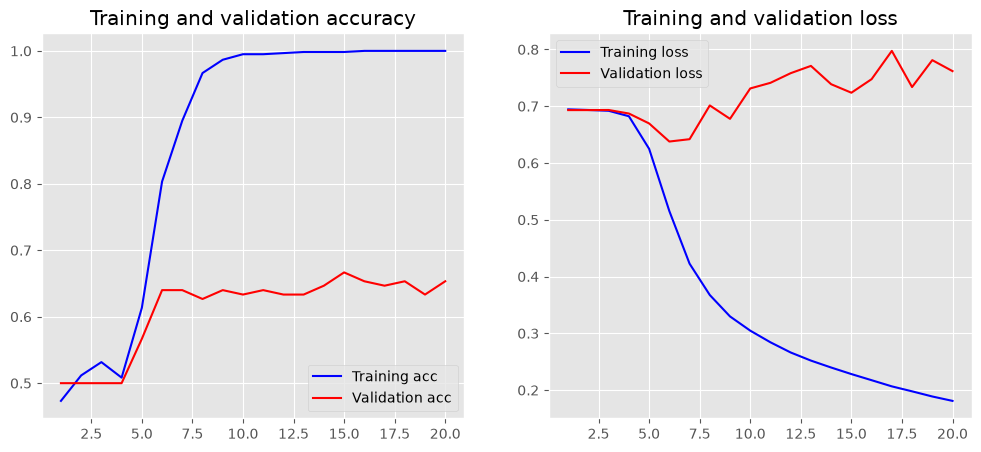

In [18]:
history = model.fit(X_train, y_train,
                    epochs=20,
                    verbose=False,
                    validation_split = 0.2,
                    batch_size=10)
loss, accuracy = model.evaluate(X_train, y_train, verbose=False)
print("Training Accuracy: {:.4f}".format(accuracy))
loss, accuracy = model.evaluate(X_test, y_test, verbose=False)
print("Testing Accuracy:  {:.4f}".format(accuracy))
plot_history(history)

This is usually **not a good way** to work with sequences. The `Flatten` model treats every position separately. For text we prefer methods that look at *local patterns*, not at exact positions.

A better way is **pooling** after the embedding. Pooling makes the data smaller. **Global max pooling** takes, for each of the 50 numbers, the *biggest value over all words* in the sentence. The result is one vector with 50 numbers, however long the sentence is. (Global *average* pooling takes the average, but max pooling is more common because it highlights big values.)

A small example with 3 words and 3 numbers each:

In [19]:
import numpy as np

emb = np.array([[ 0.1, -0.5, 0.3],    # word 1
                [ 0.7,  0.2, -0.1],   # word 2
                [-0.3,  0.9, 0.0]])   # word 3
print("shape:", emb.shape, "  (3 words x 3 numbers)")
print("global max pooling:", emb.max(axis=0))

shape: (3, 3)   (3 words x 3 numbers)
global max pooling: [0.7 0.9 0.3]


Pooling keeps, for every number, the largest value. The word order and the positions do not matter any more. What remains is: "is there a word with a strong signal here, anywhere in the sentence?"

In [20]:
from keras.models import Sequential
from keras import layers

embedding_dim = 50

model = Sequential()
model.add(layers.Input(shape=(maxlen,), dtype='int32'))
model.add(layers.Embedding(input_dim=vocab_size,
                           output_dim=embedding_dim))
model.add(layers.GlobalMaxPool1D())
model.add(layers.Dense(10, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 50)        │        87,350 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d            │ (None, 50)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,871 (343.25 KB)

 Trainable params: 87,871 (343.25 KB)

 Non-trainable params: 0 (0.00 B)

The training is the same as before:

Training Accuracy: 0.9467
Testing Accuracy:  0.8160


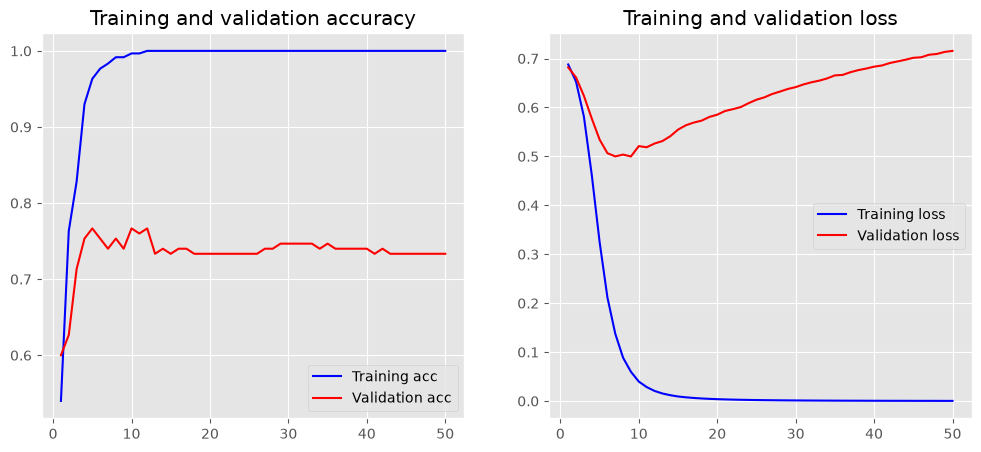

In [21]:
history = model.fit(X_train, y_train,
                    epochs=50,
                    verbose=False,
                    validation_split = 0.2,
                    batch_size=10)
loss, accuracy = model.evaluate(X_train, y_train, verbose=False)
print("Training Accuracy: {:.4f}".format(accuracy))
loss, accuracy = model.evaluate(X_test, y_test, verbose=False)
print("Testing Accuracy:  {:.4f}".format(accuracy))
plot_history(history)

Compared with the `Flatten` model (test accuracy 0.6160), pooling is better (0.8000). But it is still not better than the logistic-regression baseline (0.796). Next we use pretrained word embeddings.

#### 🛠️ Modify
Change the size of the embedding and the number of epochs, and see what happens to the test accuracy. Try `EMB_DIM` = 10, 50, 200 and `EPOCHS` = 5, 10, 50. Write your results in a table.

In [22]:
EMB_DIM = 10     # TODO: try 10, 50, 200
EPOCHS = 10      # TODO: try 5, 10, 50

m = Sequential()
m.add(layers.Input(shape=(maxlen,), dtype='int32'))
m.add(layers.Embedding(input_dim=vocab_size, output_dim=EMB_DIM))
m.add(layers.GlobalMaxPool1D())
m.add(layers.Dense(10, activation='relu'))
m.add(layers.Dense(1, activation='sigmoid'))
m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
m.fit(X_train, y_train, epochs=EPOCHS, verbose=False, validation_split=0.2, batch_size=10)
test_acc = m.evaluate(X_test, y_test, verbose=False)[1]
print("embedding_dim={}, epochs={}: test accuracy = {:.4f}".format(EMB_DIM, EPOCHS, test_acc))

embedding_dim=10, epochs=10: test accuracy = 0.7480


#### 🐞 Debug
This model must give **one probability for each sentence**: output shape `(None, 1)`. Run the cell, look at the last output shape in the summary, and fix the model.

In [23]:
bug_model = Sequential()
bug_model.add(layers.Input(shape=(maxlen,), dtype='int32'))
bug_model.add(layers.Embedding(input_dim=vocab_size, output_dim=50))
bug_model.add(layers.Dense(10, activation='relu'))
bug_model.add(layers.Dense(1, activation='sigmoid'))
bug_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 100, 50)        │        87,350 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 100, 10)        │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 100, 1)         │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,871 (343.25 KB)

 Trainable params: 87,871 (343.25 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# ✍️ Write your fixed model here and print its summary
no_bug_model = Sequential()
no_bug_model.add(layers.Input(shape=(maxlen,), dtype='int32'))
no_bug_model.add(layers.Embedding(input_dim=vocab_size, output_dim=50))
no_bug_model.add(layers.GlobalAveragePooling1D())
no_bug_model.add(layers.Dense(10, activation='relu'))
no_bug_model.add(layers.Dense(1, activation='sigmoid'))
no_bug_model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_6 (Embedding)         │ (None, 100, 50)        │        87,350 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 50)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,871 (343.25 KB)

 Trainable params: 87,871 (343.25 KB)

 Non-trainable params: 0 (0.00 B)

#### 📚 Learn more
- [Keras: Embedding layer](https://keras.io/api/layers/core_layers/embedding/) *(documentation)*: all arguments of `Embedding`.
- [Keras: TextVectorization layer](https://keras.io/api/layers/preprocessing_layers/text/text_vectorization/) *(documentation)*: the modern Keras way to tokenize text (can be part of the model).
- [Keras example: Text classification from scratch](https://keras.io/examples/nlp/text_classification_from_scratch/) *(tutorial)*: a complete example with `TextVectorization`.
- [Keras guide: Migrating to Keras 3](https://keras.io/guides/migrating_to_keras_3/) *(documentation)*: why `Tokenizer` and some arguments are gone.

### 📝 Quick check 1
**Q1 (code reading).** `pad_sequences(seqs, padding='post', maxlen=100)`: what happens to a sentence with 13 words, and to a sentence with 120 words?

**Q2 (code tracing).** How many trainable parameters does `layers.Embedding(input_dim=1747, output_dim=50)` have?

**Q3 (true/false, explain).** "`GlobalMaxPool1D` keeps the order of the words in the sentence."

**Q4 (short answer).** Why do we write `vocab_size = len(tokenizer.word_index) + 1`?

<details>
<summary><b>✅ Check Your Answers: Section 2</b></summary>

**Observe 1:** "the" is **1**. The tokenizer numbers words by frequency, and "the" is the most frequent word. (The word "all" = 43 appears two times and is 43 both times.)
**Observe 2:** number 0 is only for padding. The real words are 1…1746, so the table needs 1747 rows.

**Think (1714 vs 1746):** the two tools split text in different ways. For example, `CountVectorizer` ignores one-letter words ("a", "I") by default, but the tokenizer keeps them. They also treat apostrophes and punctuation differently.

**Shape after padding:** `X_train.shape` is `(750, 100)`. `X_train[2]` is the 13 word numbers followed by 87 zeros.

**Predict (Flatten model):** after `Flatten`: 100 × 50 = **5000** numbers. `Dense(10)` has 5000 × 10 + 10 = **50,010** parameters. (The Embedding layer has 1747 × 50 = 87,350.)

**Modify:** check your own numbers. Expect differences of a few points between settings and between runs. A bigger embedding and more epochs mean more parameters and easier overfitting with 750 sentences.

**Debug:** a `Dense` layer works only on the *last* axis. The Embedding output is 3-D, `(None, 100, 50)`, so it stays 3-D. The summary ends with `(None, 100, 1)`: one probability for every *word position*. Add `layers.GlobalMaxPool1D()` (or `layers.Flatten()`) between the Embedding and the first Dense layer. Fixed code:
```python
ok_model = Sequential()
ok_model.add(layers.Input(shape=(maxlen,), dtype='int32'))
ok_model.add(layers.Embedding(input_dim=vocab_size, output_dim=50))
ok_model.add(layers.GlobalMaxPool1D())          # <-- the missing layer
ok_model.add(layers.Dense(10, activation='relu'))
ok_model.add(layers.Dense(1, activation='sigmoid'))
ok_model.summary()                              # last output shape: (None, 1)
```

**Q1:** the sentence with 13 words gets 87 zeros at the end. The sentence with 120 words is cut to 100 words (by default the *first* words are removed).

**Q2:** 1747 × 50 = **87,350** (one vector of 50 numbers per row; no biases).

**Q3: False.** Pooling takes the maximum for each number over all positions, so we lose where a word was. (The `Flatten` model keeps the positions, but it treats each position separately.)

**Q4:** Number 0 is reserved for padding and is not in `word_index`. The embedding table needs one extra row for it.

</details>

## 3. Pretrained word embeddings (GloVe)

**Idea:** with only 750 sentences it is hard to learn good embeddings. Instead we can start with vectors that were trained on **billions of words**. Then we can **freeze** them (`trainable=False`) or let the network **fine-tune** them (`trainable=True`).

We use the GloVe vectors from the Stanford NLP Group: the "6B" version (trained on 6 billion words), file `glove.6B.zip`, **822 MB**, from [the GloVe page](https://nlp.stanford.edu/projects/glove/). The next two cells download and unzip it.

In [ ]:
# !wget https://nlp.stanford.edu/data/glove.6B.zip
!wget https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip

--2026-11-08 06:53:39--  https://huggingface.co/stanfordnlp/glove/resolve/main/glove.6B.zip
Resolving huggingface.co (huggingface.co)... 3.165.63.112, 3.165.63.125, 3.165.63.40, ...
Connecting to huggingface.co (huggingface.co)|3.165.63.112|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://us.gcp.cdn.hf.co/xet-bridge-us/621ffdc136468d709f18095d/ded22944ac944002f423d1cdb83de044851330e1a7fe19d74dc59ffa632ad294?response-content-disposition=inline%3B+filename*%3DUTF-8%27%27glove.6B.zip%3B+filename%3D%22glove.6B.zip%22%3B&user_id=public&xip=anY9T1bxxjs&response-content-type=application%2Fzip&X-Xet-Cas-Uid=public&Expires=1794124420&Policy=eyJTdGF0ZW1lbnQiOlt7IlJlc291cmNlIjoiaHR0cHM6Ly91cy5nY3AuY2RuLmhmLmNvL3hldC1icmlkZ2UtdXMvNjIxZmZkYzEzNjQ2OGQ3MDlmMTgwOTVkL2RlZDIyOTQ0YWM5NDQwMDJmNDIzZDFjZGI4M2RlMDQ0ODUxMzMwZTFhN2ZlMTlkNzRkYzU5ZmZhNjMyYWQyOTRcXD9yZXNwb25zZS1jb250ZW50LWRpc3Bvc2l0aW9uPSomdXNlcl9pZD1wdWJsaWMmeGlwPWFuWTlUMWJ4eGpzJnJlc3BvbnNlLWNvbnRlbnQtdHlwZT

In [ ]:
!unzip 'glove.6B.zip' -d 'data'

Archive:  glove.6B.zip
  inflating: data/glove.6B.100d.txt  
  inflating: data/glove.6B.200d.txt  
  inflating: data/glove.6B.300d.txt  
  inflating: data/glove.6B.50d.txt   


You can find other embeddings on the GloVe page. Google's word2vec embeddings are also available. You can train your own embeddings with the `gensim` package.

Each line of the GloVe file starts with a word, followed by the numbers of its vector. The file has 400,000 lines. Here are the first characters of the first line:

In [ ]:
 # the 0.418 0.24968 -0.41242 0.1217 0.34527 -0.04445

We do not need all 400,000 words. We only need the words of **our** vocabulary. The function below reads the file line by line and keeps only those words. It builds a table (`embedding_matrix`) with one row for every word number.

In [ ]:
import numpy as np

def create_embedding_matrix(filepath, word_index, embedding_dim):
    vocab_size = len(word_index) + 1  # Adding again 1 because of reserved 0 index
    embedding_matrix = np.zeros((vocab_size, embedding_dim))

    with open(filepath, encoding='utf8') as f:
        for line in f:
            word, *vector = line.split()
            if word in word_index:
                idx = word_index[word]
                embedding_matrix[idx] = np.array(
                    vector, dtype=np.float32)[:embedding_dim]

    return embedding_matrix

*Change note:* I added `encoding='utf8'`, so the file also loads on systems where the default encoding is not UTF-8 (for example Windows).

#### ✍️ Explain
In your own words: what does `create_embedding_matrix` build? Think about the shape of `embedding_matrix`, what row *i* contains, and what happens to words that are not in the GloVe file.

**✏️ Your answer:**

for every word in our file, it stores its embedding vector, word is row, and columns are the embedding of that word


Now use the function for our vocabulary:

In [ ]:
embedding_dim = 50
embedding_matrix = create_embedding_matrix(
    'data/glove.6B.50d.txt',
    # 'GoogleNews-vectors-negative300.bin',
    tokenizer.word_index, embedding_dim)

Now we can use the matrix in a model. We use the network with global max pooling from before. With pretrained embeddings we can choose: **freeze** the vectors, or **train** them too.

First: how many words of our vocabulary have a vector (a row that is not all zeros)?

In [ ]:
nonzero_elements = np.count_nonzero(np.count_nonzero(embedding_matrix, axis=1))
nonzero_elements / vocab_size

np.float64(0.9507727532913566)

About 95.1 % of our vocabulary is covered by GloVe. That is good coverage. (The other words keep a row of zeros.) First test: **frozen** embeddings.

In [ ]:
model = Sequential()
model.add(layers.Input(shape=(maxlen,), dtype='int32'))
model.add(layers.Embedding(vocab_size, embedding_dim,
                           embeddings_initializer=keras.initializers.Constant(embedding_matrix),
                           trainable=False))
model.add(layers.GlobalMaxPool1D())
model.add(layers.Dense(10, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 100, 50)        │        87,350 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_2          │ (None, 50)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,871 (343.25 KB)

 Trainable params: 521 (2.04 KB)

 Non-trainable params: 87,350 (341.21 KB)

*Change note:* the old code used `weights=[embedding_matrix]` in the `Embedding` layer. Keras 3 uses `embeddings_initializer=keras.initializers.Constant(embedding_matrix)` to set the start values.

#### 👀 Observe
Look at the end of the summary: how many parameters are *trainable* and how many are *non-trainable*? Which layers do they belong to?

Training Accuracy: 0.7653
Testing Accuracy:  0.6960


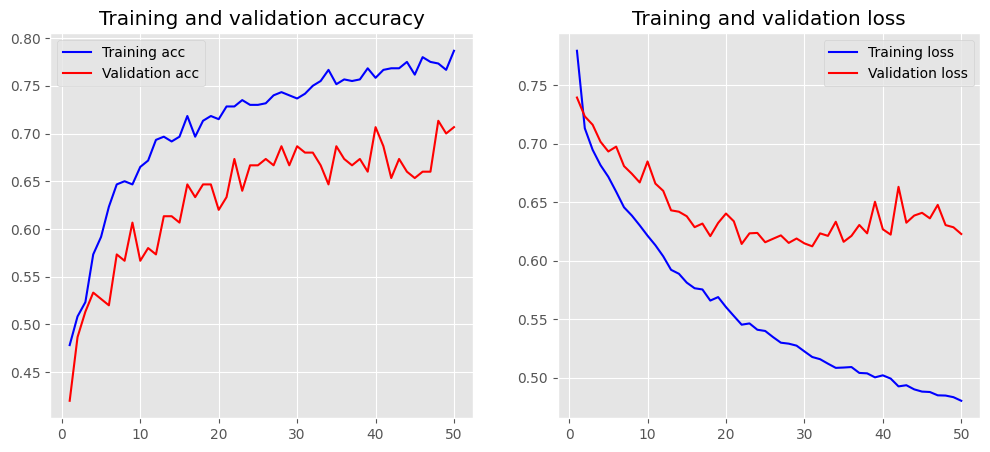

In [ ]:
history = model.fit(X_train, y_train,
                    epochs=50,
                    verbose=False,
                    validation_split = 0.2,
                    batch_size=10)
loss, accuracy = model.evaluate(X_train, y_train, verbose=False)
print("Training Accuracy: {:.4f}".format(accuracy))
loss, accuracy = model.evaluate(X_test, y_test, verbose=False)
print("Testing Accuracy:  {:.4f}".format(accuracy))
plot_history(history)

Because the embeddings are not trained, we expect a lower result. Now let the embeddings be trained: `trainable=True`.

In [ ]:
model = Sequential()
model.add(layers.Input(shape=(maxlen,), dtype='int32'))
model.add(layers.Embedding(vocab_size, embedding_dim,
                           embeddings_initializer=keras.initializers.Constant(embedding_matrix),
                           trainable=True))
model.add(layers.GlobalMaxPool1D())
model.add(layers.Dense(10, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_5 (Embedding)         │ (None, 100, 50)        │        87,350 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_3          │ (None, 50)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,871 (343.25 KB)

 Trainable params: 87,871 (343.25 KB)

 Non-trainable params: 0 (0.00 B)

Training Accuracy: 0.9467
Testing Accuracy:  0.7320


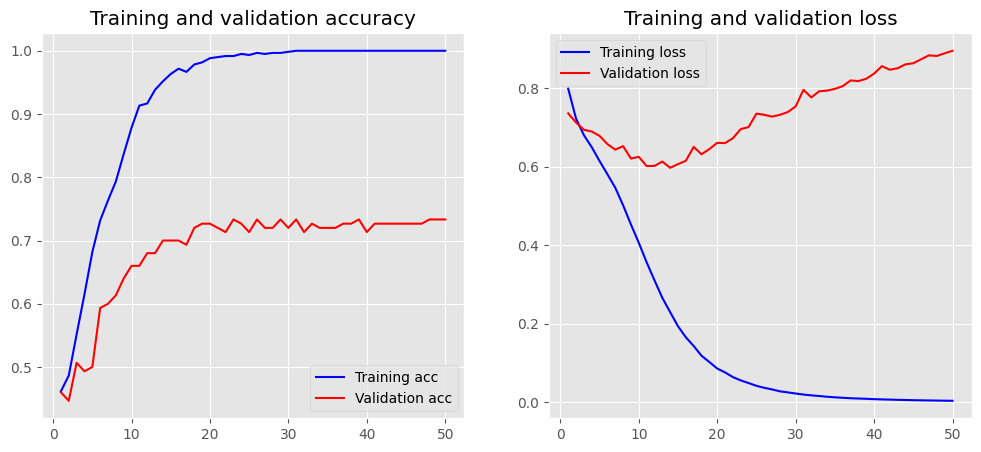

In [ ]:
history = model.fit(X_train, y_train,
                    epochs=50,
                    verbose=False,
                    validation_split = 0.2,
                    batch_size=10)
loss, accuracy = model.evaluate(X_train, y_train, verbose=False)
print("Training Accuracy: {:.4f}".format(accuracy))
loss, accuracy = model.evaluate(X_test, y_test, verbose=False)
print("Testing Accuracy:  {:.4f}".format(accuracy))
plot_history(history)

In our runs, training the embeddings helped compared with freezing them (test accuracy 0.7520 vs 0.7000). But the pretrained vectors did **not** beat the random embeddings from Section 2 (0.7800). With only 750 training sentences, differences of a few points are noise. Pretrained embeddings help most when you have *little* data *and* the words of your task are well covered by the pretrained vocabulary.

#### 🤔 Think
The frozen model has a *low training accuracy* (0.7440). All earlier models had a high one. Why? And why can the trainable model reach 0.9547 on the training data?

**✏️ Your answer:**

it is normal, and we notice that the accuracy is close to the test accuracy, since our training dataset is a test dataset for the frozen model since he had not train on it


#### 🛠️ Modify
GloVe also has 100-number vectors (`glove.6B.100d.txt` was unzipped too). Run the next cell with `GLOVE_DIM = 100` (then 200) and compare the test accuracy with the 50-number result.

In [ ]:
GLOVE_DIM = 100      # TODO: try 50, 100, 200

glove_matrix = create_embedding_matrix(
    'data/glove.6B.{}d.txt'.format(GLOVE_DIM), tokenizer.word_index, GLOVE_DIM)

g = Sequential()
g.add(layers.Input(shape=(maxlen,), dtype='int32'))
g.add(layers.Embedding(vocab_size, GLOVE_DIM,
                       embeddings_initializer=keras.initializers.Constant(glove_matrix),
                       trainable=True))
g.add(layers.GlobalMaxPool1D())
g.add(layers.Dense(10, activation='relu'))
g.add(layers.Dense(1, activation='sigmoid'))
g.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
g.fit(X_train, y_train, epochs=50, verbose=False, validation_split=0.2, batch_size=10)
print("GloVe {}d, trainable: test accuracy = {:.4f}".format(
    GLOVE_DIM, g.evaluate(X_test, y_test, verbose=False)[1]))

GloVe 100d, trainable: test accuracy = 0.7680


#### 📚 Learn more
- [GloVe project page (Stanford)](https://nlp.stanford.edu/projects/glove/) *(project page)*: the vectors and a short description.
- [Pennington et al. (2014): GloVe: Global Vectors for Word Representation](https://aclanthology.org/D14-1162/) *(paper)*: the GloVe paper.
- [Keras example: Using pre-trained word embeddings](https://keras.io/examples/nlp/pretrained_word_embeddings/) *(tutorial)*: the same idea (GloVe in a Keras model) with Keras 3 code.
- [fastText](https://fasttext.cc/) *(project page)*: embeddings that also work for unknown and misspelled words.

### 📝 Quick check 2
**Q1 (multiple choice).** What does `trainable=False` in the `Embedding` layer do?
- A. It removes the embedding layer from the model
- B. The weights of the embedding are not changed during training
- C. It makes training faster by skipping the Dense layers
- D. It sets all embedding vectors to zero

**Q2 (code tracing).** What is the shape of `embedding_matrix`? What is in row 0?

**Q3 (short answer).** The coverage is about 95 %. What happens to the other ≈ 5 % of the words?

**Q4 (true/false, explain).** "Pretrained embeddings always give a higher test accuracy than random embeddings."

<details>
<summary><b>✅ Check Your Answers: Section 3</b></summary>

**Explain:** it builds a table with shape `(vocab_size, embedding_dim)` = (1747, 50). Row *i* has the GloVe vector of the word with number *i*. Words that are not in the GloVe file (and the padding number 0) stay as rows of zeros.

**Observe:** only **521** parameters are trainable (the two Dense layers: 510 + 11). **87,350** are non-trainable (the Embedding layer: 1747 × 50).

**Think:** with frozen embeddings only 521 weights can change, so the model cannot fit the training data well (underfitting). Also, general GloVe vectors capture the *meaning from context*, not the *feeling*. Words like "good" and "bad" appear in similar contexts, so they can get similar vectors. When the embeddings are trainable, 87,350 more weights can change. That is enough to remember 600 sentences (and to overfit: the test accuracy is lower).

**Modify:** check your own numbers. Do not expect a big, steady gain from more dimensions on such a small data set.

**Q1: B.** The weights stay fixed. (The layer is still used.)

**Q2:** `(1747, 50)`, which is `(vocab_size, embedding_dim)`. Row 0 (padding) is all zeros.

**Q3:** Their rows stay all zeros. A frozen model cannot learn anything for them. A trainable model can learn vectors for them from our data.

**Q4: False.** In our runs, GloVe (trainable) got 0.7520 and random embeddings got 0.7800. Pretrained vectors help most with little data and good coverage, but they do not always win.

</details>

## 4. Convolutional neural networks (CNN)

A **convolutional neural network** (CNN, or "convnet") became famous for images. It can also work well on sequences such as text. You can think of a CNN as a network that is good at finding **patterns**.

What is different from the networks you know? A CNN has **convolutional layers**. A convolutional layer has many **filters**. A filter is a small window that **slides** over the data and looks for one pattern. For images, filters find edges, corners and textures. With more layers, the network finds more complex patterns.

For text we use **one-dimensional** convolutions. The idea is the same: find patterns in the sequence. A filter takes a patch of the input (the size of the patch is the *kernel size*), multiplies it with its weights and adds the results (a dot product). Then it moves one step further.

A 1-D CNN finds a pattern **wherever it is** in the sentence. This is good for text. The next picture shows how a convolution works:

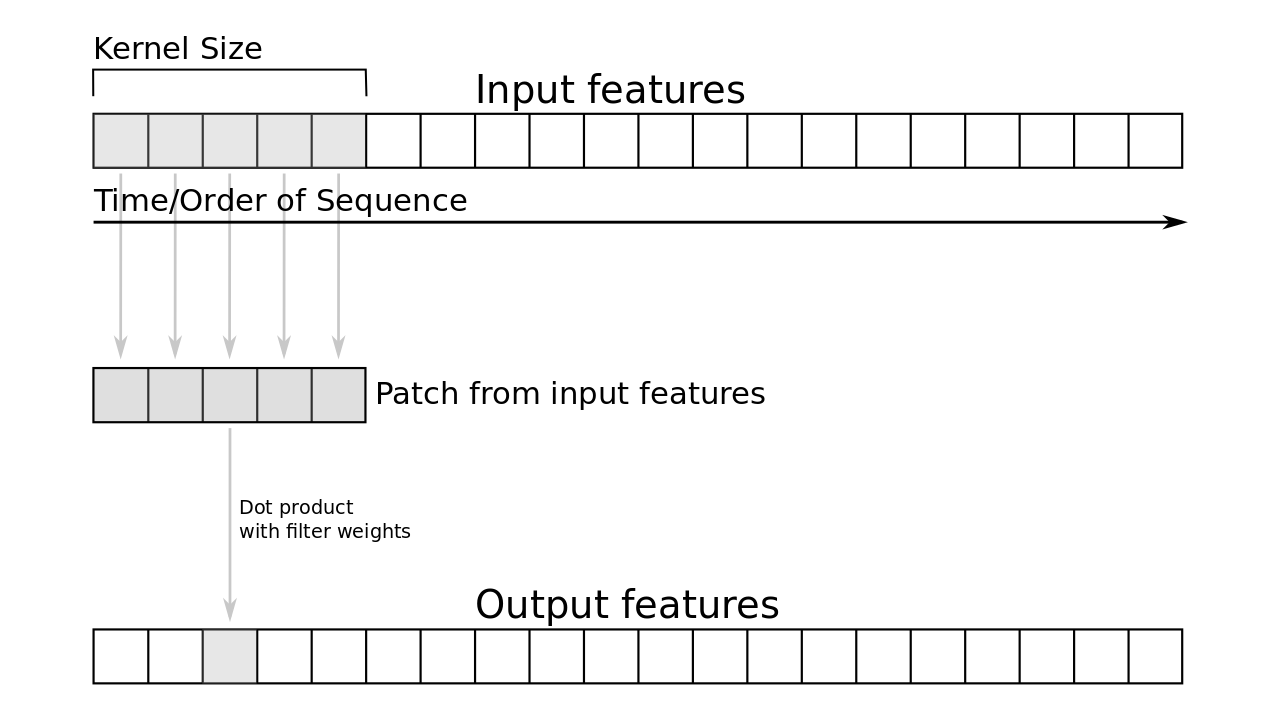

**In text terms:** a filter looks at a **window of `kernel_size` neighbouring words** (their embeddings) and gives one number for the window. Then it slides over the sentence one word at a time. A layer with 128 filters learns 128 different patterns (such as "not good" or "really great"). Global max pooling then keeps, for each filter, the **strongest match anywhere** in the sentence.

A small example. `neg` marks which of 6 words are negative (1) or not (0). A filter of size 3 with weights `[1, 1, 1]` counts the negative words in every window of 3 words:

In [ ]:
import numpy as np

neg = np.array([0, 0, 1, 1, 0, 0])      # 6 words, words 3 and 4 are "negative"
kernel = np.array([1, 1, 1])             # window of 3 words
k = len(kernel)

windows = [int(neg[i:i + k] @ kernel) for i in range(len(neg) - k + 1)]
print("window scores:", windows, "  (6 - 3 + 1 =", len(windows), "windows)")
print("global max   :", max(windows))

window scores: [1, 2, 2, 1]   (6 - 3 + 1 = 4 windows)
global max   : 2


In Keras we use the `Conv1D` layer. Important arguments: the number of filters, the kernel size and the activation function. We put it between the Embedding layer and the pooling layer:

#### 🔮 Predict
The next model has `Embedding(vocab_size, 100)` for sentences of length 100, followed by `Conv1D(128, 5)`. Guess: (a) the output shape of the `Conv1D` layer; (b) its number of parameters. (Each of the 128 filters has weights for 5 words × 100 numbers, plus 1 bias. The old output was removed on purpose.)

**✏️ Your guess:**

In [ ]:
embedding_dim = 100

model = Sequential()
model.add(layers.Input(shape=(maxlen,), dtype='int32'))
model.add(layers.Embedding(vocab_size, embedding_dim))
model.add(layers.Conv1D(128, 5, activation='relu'))
model.add(layers.GlobalMaxPooling1D())
model.add(layers.Dense(10, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))
model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_7 (Embedding)         │ (None, 100, 100)       │       174,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 96, 128)        │        64,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_5          │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │         1,290 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 240,129 (938.00 KB)

 Trainable params: 240,129 (938.00 KB)

 Non-trainable params: 0 (0.00 B)

Training Accuracy: 0.9560
Testing Accuracy:  0.7840


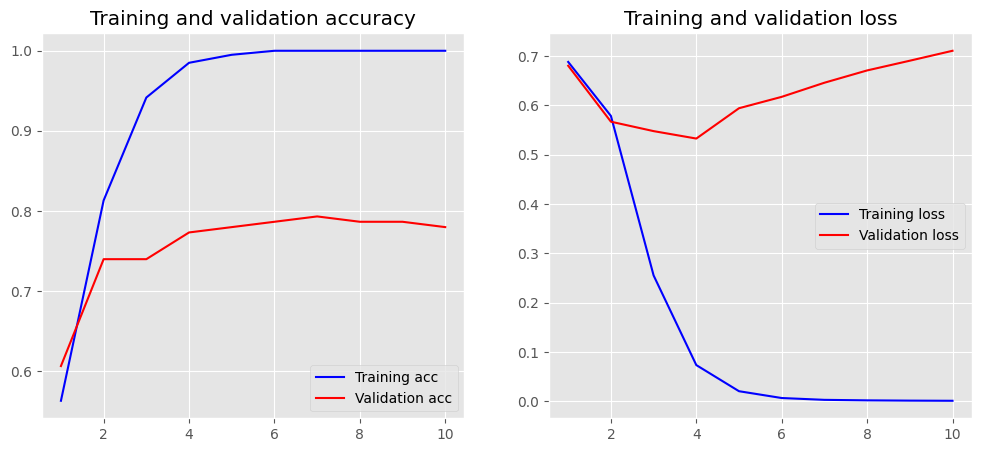

In [ ]:
history = model.fit(X_train, y_train,
                    epochs=10,
                    verbose=False,
                    validation_split = 0.2,
                    batch_size=10)
loss, accuracy = model.evaluate(X_train, y_train, verbose=False)
print("Training Accuracy: {:.4f}".format(accuracy))
loss, accuracy = model.evaluate(X_test, y_test, verbose=False)
print("Testing Accuracy:  {:.4f}".format(accuracy))
plot_history(history)

The CNN gets 0.7840 test accuracy. That is not better than the other models, and lower than the logistic-regression baseline (0.796). Accuracy seems hard to improve with this data set. Possible reasons:

- There are not enough training samples.
- The data does not generalize well.
- We did not tune the hyperparameters (see Appendix B).

CNNs work best with **large** training sets, where they can find patterns that a simple model like logistic regression cannot.

#### 📚 Learn more
- [Kim (2014): Convolutional Neural Networks for Sentence Classification](https://arxiv.org/abs/1408.5882) *(paper)*: the classic paper about CNNs for text.
- [Keras: Conv1D layer](https://keras.io/api/layers/convolution_layers/convolution1d/) *(documentation)*: all arguments, and output shape.
- [Chris Olah: Understanding Convolutions](http://colah.github.io/posts/2014-07-Understanding-Convolutions/) *(article with pictures)*: a clear explanation of the idea of convolution.

### 📝 Quick check 3
**Q1 (multiple choice).** In `Conv1D(128, 5, activation='relu')`, what do 128 and 5 mean?
- A. 128 words per sentence, 5 sentences per batch
- B. 128 filters (pattern finders); each looks at windows of 5 words next to each other
- C. 128 epochs and 5 hidden layers
- D. A vocabulary of 128 words and an embedding of 5 numbers

**Q2 (code tracing).** The input of `Conv1D` has shape `(None, 100, 100)`, `kernel_size=5`, no padding. What is the output shape?

**Q3 (true/false, explain).** "A CNN is a more advanced model. So it must be better than logistic regression on this data set."

<details>
<summary><b>✅ Check Your Answers: Section 4</b></summary>

**Predict:** output length = 100 − 5 + 1 = 96, so the shape is **(None, 96, 128)**. Parameters: (5 × 100 + 1) × 128 = **64,128**.

**Q1: B.**

**Q2:** `(None, 96, 128)`: 100 − 5 + 1 = 96 positions, and 128 channels (one for each filter).

**Q3: False.** In our run the CNN got 0.7680, and logistic regression got 0.796. CNNs usually need large training sets. We have 750 sentences.

</details>

## 5. 🏁 Exercise B: find unhappy customers

### The story
An online shop sells phone accessories. It gets thousands of review sentences. The support team wants a tool that **finds negative reviews** automatically, so they can answer these first. Your job: build and compare two models on the **Amazon** part of the data. (It is a new topic compared with the Yelp sentences. The data is already in `df` from the recap (Section 1), so you do not need a new download.)

You use what you learned: train/test split, a bag-of-words baseline, a tokenizer with `pad_sequences`, an `Embedding` + pooling network, a validation curve to choose the number of epochs, and a final comparison.

### What you should have at the end
- the **test accuracy of the baseline** (CountVectorizer + logistic regression);
- the **test accuracy of the embedding network**, trained for a good number of epochs;
- a short conclusion: which model is better, and is the difference important?
- predictions for new reviews.

### Rules and tips
- Replace the `...` and the `# TODO` lines. Cells with `...` **give an error until you finish them**. This is normal. Use *Run selected cell*, not *Run all*, while you work here.
- Variable names start with `am_`, so you do not change variables from earlier sections.
- The `SimpleTokenizer` class from Section 2 and the functions `plot_history` (Section 1) must be defined. Run those cells first.
- Open the 💡 hints if you are stuck. Look at the solutions (Section 6) only after you tried.
- Your accuracy will not be exactly the same as others' accuracy. Neural networks start with random weights.

### Step 0: look at the data (given)

In [6]:
df_amz = df[df['source'] == 'amazon']
am_sentences = df_amz['sentence'].values
am_y = df_amz['label'].values

print("number of sentences:", len(am_sentences))
print("label counts (0 = negative, 1 = positive):", {0: int((am_y == 0).sum()), 1: int((am_y == 1).sum())})
for label, text in list(zip(am_y, am_sentences))[:5]:
    print(label, "|", text)

number of sentences: 1000
label counts (0 = negative, 1 = positive): {0: 500, 1: 500}
0 | So there is no way for me to plug it in here in the US unless I go by a converter.
1 | Good case, Excellent value.
1 | Great for the jawbone.
0 | Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
1 | The mic is great.


### Step 1: split the data
Split `am_sentences` and `am_y` into 75 % training data and 25 % test data. Use `random_state=1000`.
<details>
<summary><b>💡 Hint 1</b></summary>

You did this in Notebook A, Section 2 with `train_test_split`. It returns four things in this order: training sentences, test sentences, training labels, test labels.

</details>

In [7]:
from sklearn.model_selection import train_test_split

# TODO: replace ... with a call to train_test_split
am_sent_train, am_sent_test, am_y_train, am_y_test = train_test_split(am_sentences, am_y, test_size=0.25, random_state=1000)

print(len(am_sent_train), len(am_sent_test))

750 250


### Step 2: the baseline
Build the baseline: make count vectors with `CountVectorizer` (the vocabulary only from the **training** sentences), train a `LogisticRegression`, and calculate the **test accuracy** in `am_baseline_acc`.
<details>
<summary><b>💡 Hint 2</b></summary>

Order: make the vectorizer → `fit` on the training sentences → `transform` both sets → make and `fit` the classifier on the training matrix → `score` on the *test* matrix. Do not fit anything on the test data.

</details>

In [32]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

# TODO 2a: make and fit the vectorizer, transform the train and test sentences
am_vectorizer = CountVectorizer()
am_vectorizer.fit(am_sent_train)
am_x_train_vec = am_vectorizer.transform(am_sent_train)
am_x_test_vec = am_vectorizer.transform(am_sent_test)
# TODO 2b: make and fit the classifier
am_baseline = LogisticRegression()
am_baseline.fit(am_x_train_vec, am_y_train)
am_baseline_acc = am_baseline.score(am_x_test_vec, am_y_test)      # TODO 2c: test accuracy

print("Baseline test accuracy:", am_baseline_acc)

Baseline test accuracy: 0.796


### Step 3: prepare the data for an embedding model
1. Fit a `SimpleTokenizer(num_words=5000)` on the **training** sentences. Change the training and test sentences to number sequences.
2. Calculate `am_vocab_size` (do not forget the `+ 1`).
3. Choose `am_maxlen`. Amazon sentences are short, so you do not need 100. Use the **length of the longest training sequence**.
4. Pad the sequences with `pad_sequences(..., padding='post', maxlen=am_maxlen)`. Call the results `am_X_train` and `am_X_test`.
<details>
<summary><b>💡 Hint 3</b></summary>

`tokenizer.texts_to_sequences(...)` gives a list of lists. The longest one: `max(len(s) for s in am_seq_train)`. Look at Section 2 for the exact calls.

</details>

In [33]:
from keras.utils import pad_sequences

am_tokenizer = SimpleTokenizer(num_words=5000)
am_tokenizer.fit_on_texts(am_sent_train)
am_seq_train = am_tokenizer.texts_to_sequences(am_sent_train)
am_seq_test = am_tokenizer.texts_to_sequences(am_sent_test)

vocab_size = len(am_tokenizer.word_index) + 1

# TODO 3a: tokenizer -> am_seq_train, am_seq_test
am_vocab_size = len(am_tokenizer.word_index) + 1        # TODO 3b
am_maxlen = max(len(sent) for sent in am_seq_train)            # TODO 3c
# TODO 3d: pad -> am_X_train, am_X_test
am_X_train = pad_sequences(am_seq_train,padding='post',maxlen= am_maxlen)
am_X_test = pad_sequences(am_seq_test,padding='post',maxlen= am_maxlen)
print("vocab size:", am_vocab_size, " maxlen:", am_maxlen, " train shape:", am_X_train.shape)

vocab size: 1574  maxlen: 29  train shape: (750, 29)


### Step 4: build the model
Write a function `build_am_model(vocab_size, maxlen)` that returns a **compiled** Keras model:
`Input` → `Embedding(output_dim=50)` → `GlobalMaxPool1D` → `Dense(10, relu)` → `Dense(1, sigmoid)`. Use `adam`, `binary_crossentropy` and the metric `accuracy`.

**Why a function?** To train again from the start you need a *new* model. If you call `.fit()` again on the same model, it continues with the old weights (see Notebook A, Section 3).
<details>
<summary><b>💡 Hint 4</b></summary>

It is the same model as the `GlobalMaxPool1D` model in Section 2. The first layer is `layers.Input(shape=(maxlen,), dtype='int32')`. Do not forget `return`.

</details>

In [34]:
from keras.models import Sequential
from keras import layers

def build_am_model(vocab_size, maxlen):
    # TODO: build, compile and return the model
    model = Sequential()
    model.add(layers.Input(shape=(maxlen,), dtype='int32'))
    model.add(layers.Embedding(input_dim=vocab_size,
                           output_dim=50))
    model.add(layers.GlobalMaxPool1D())
    model.add(layers.Dense(10, activation='relu'))
    model.add(layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])
    return model
build_am_model(am_vocab_size, am_maxlen).summary()

Model: "sequential_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_13 (Embedding)        │ (None, 29, 50)         │        78,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_13         │ (None, 50)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,221 (309.46 KB)

 Trainable params: 79,221 (309.46 KB)

 Non-trainable params: 0 (0.00 B)

### Step 5: choose the number of epochs, then train the final model
1. Train a model for **30 epochs** with `validation_split=0.2` and `batch_size=10`. Draw the curves with `plot_history`.
2. Find the epoch with the **lowest validation loss** (`am_best_epoch`). Hint: use `np.argmin` on `history.history['val_loss']`. Epochs count from 1.
3. Build a **new** model and train it for `am_best_epoch` epochs. Calculate its **test accuracy** `am_nn_acc`.
<details>
<summary><b>💡 Hint 5</b></summary>

`history.history['val_loss']` is a list with one number per epoch. `int(np.argmin(values)) + 1` is the best epoch. Use `model.evaluate(X_test, y_test, verbose=False)`. It returns `[loss, accuracy]`.

</details>

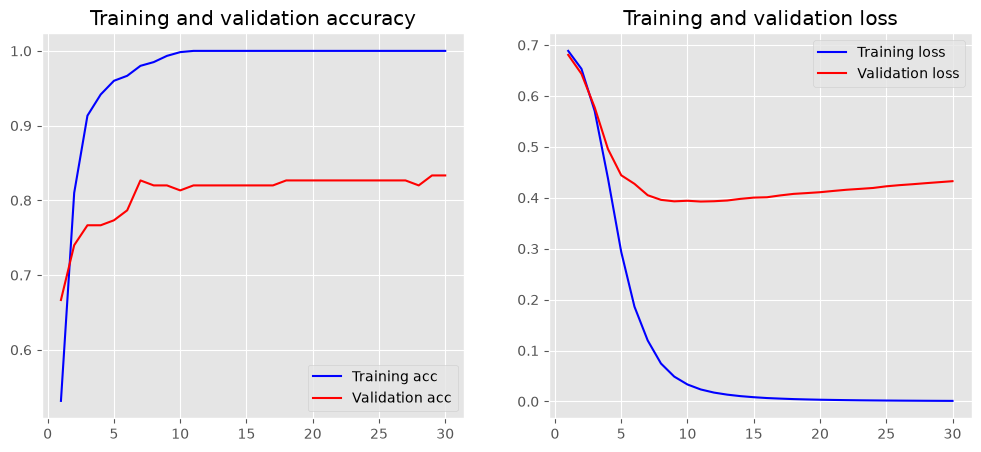

In [35]:
import numpy as np
model = build_am_model(am_vocab_size,am_maxlen)
am_history = model.fit(am_X_train, am_y_train,
                    epochs=30,
                    verbose=False,
                    validation_split = 0.2,
                    batch_size=10)
# history = model.fit(am_X_train, am_y_train, verbose=False, epochs=30, validation_split=0.2, batch_size=10)
plot_history(am_history)


In [37]:
# TODO 5a: build a model, train 30 epochs, keep the history, draw it
am_best_epoch = int(np.argmin(am_history.history['val_loss'])) +1       # TODO 5b
print("best epoch:", am_best_epoch)


best epoch: 11


In [38]:
am_best_model = build_am_model(am_vocab_size,am_maxlen)
am_best_history = am_best_model.fit(am_X_train, am_y_train,
                    epochs=am_best_epoch,
                    verbose=False,
                    validation_split = 0.2,
                    batch_size=10)
# TODO 5c: build a NEW model, train it for am_best_epoch epochs

_,am_nn_acc = am_best_model.evaluate(am_X_test, am_y_test,verbose=False)            # TODO 5d: test accuracy
print("NN test accuracy:", am_nn_acc)

NN test accuracy: 0.7839999794960022


### Step 6: compare and write your conclusion
Print both accuracies. The test set is small, so also calculate how many *sentences* the difference means. Then write 2–3 sentences: Which model is better? By how much? Do you trust the difference? What would you do to find out more?

**✏️ Your conclusion:**

In [41]:
# TODO: print am_baseline_acc and am_nn_acc, and the difference in number of test sentences
dif =am_nn_acc - am_baseline_acc
print(am_baseline_acc, am_nn_acc, f"dif : {dif}")
print(f"Dif sent : {dif * len(am_y_test)}")

0.796 0.7839999794960022 dif : -0.012000020503997844
Dif sent : -3.000005125999461


### Step 7: use the model on new reviews
Write at least three new reviews (one of them your own). Print the probability and the label for each. Remember: new text must use the **same tokenizer and the same padding** as the training data (use `transform`-style calls, not a new `fit`).
<details>
<summary><b>💡 Hint 7</b></summary>

`texts_to_sequences` → `pad_sequences(..., maxlen=am_maxlen)` → `model.predict(...)`. The result has shape `(n, 1)`; `.ravel()` makes it flat. The label is 1 if the probability is above 0.5.

</details>

In [ ]:
new_reviews = [
    "Great sound quality, works perfectly",
    "Broke after two days. Waste of money",
    # TODO: add your own review here
]
# TODO: tokenize + pad + predict + print

### ⭐ Optional challenges (if you finish early)
1. **Look at the mistakes:** print five test sentences that your network got wrong, with the predicted probabilities. Can you see why they are difficult?
2. **Pretrained vectors:** repeat Step 5 with GloVe (`create_embedding_matrix(...)` from Section 3, `trainable=True`, with `am_tokenizer.word_index`). Does it help?
3. **CNN:** use `Conv1D(64, 3, activation='relu')` and `GlobalMaxPooling1D()` instead of the pooling model. Does it help?

## 6. Solutions to Exercise B
**Try the exercise first!** The cells below are complete and can run. They build everything again from Step 1, so they also work if you skipped the exercise. (They need the cells that define `SimpleTokenizer` and `plot_history`.) Because of random start weights, your numbers will be different each run.

### Steps 1 and 2: split and baseline
The split is the same call as in Notebook A, Section 2. The vectorizer sees only the training sentences. The test set is used once, for the final score.

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

df_amz = df[df['source'] == 'amazon']
am_sentences = df_amz['sentence'].values
am_y = df_amz['label'].values

am_sent_train, am_sent_test, am_y_train, am_y_test = train_test_split(
    am_sentences, am_y, test_size=0.25, random_state=1000)
print(len(am_sent_train), len(am_sent_test))

am_vectorizer = CountVectorizer()
am_vectorizer.fit(am_sent_train)
am_clf = LogisticRegression()
am_clf.fit(am_vectorizer.transform(am_sent_train), am_y_train)
am_baseline_acc = am_clf.score(am_vectorizer.transform(am_sent_test), am_y_test)
print("Baseline test accuracy: {:.4f}".format(am_baseline_acc))

750 250
Baseline test accuracy: 0.7960


### Step 3: tokenize and pad
`am_maxlen` is the longest *training* sequence, so no training sentence is cut. Longer test sentences (or new reviews) would be cut, and this is fine. The `+ 1` is for number 0 (padding).

In [ ]:
from keras.utils import pad_sequences

am_tokenizer = SimpleTokenizer(num_words=5000)
am_tokenizer.fit_on_texts(am_sent_train)
am_seq_train = am_tokenizer.texts_to_sequences(am_sent_train)
am_seq_test = am_tokenizer.texts_to_sequences(am_sent_test)

am_vocab_size = len(am_tokenizer.word_index) + 1
am_maxlen = max(len(s) for s in am_seq_train)

am_X_train = pad_sequences(am_seq_train, padding='post', maxlen=am_maxlen)
am_X_test = pad_sequences(am_seq_test, padding='post', maxlen=am_maxlen)
print("vocab size:", am_vocab_size, " maxlen:", am_maxlen, " train shape:", am_X_train.shape)

vocab size: 1574  maxlen: 29  train shape: (750, 29)


### Step 4: the function that builds the model
It is the same model as in Section 2. The function returns a *new compiled model* each time, so every training starts with random weights.

In [30]:
from keras.models import Sequential
from keras import layers

def build_am_model(vocab_size, maxlen):
    m = Sequential()
    m.add(layers.Input(shape=(maxlen,), dtype='int32'))
    m.add(layers.Embedding(input_dim=vocab_size, output_dim=50))
    m.add(layers.GlobalMaxPool1D())
    m.add(layers.Dense(10, activation='relu'))
    m.add(layers.Dense(1, activation='sigmoid'))
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return m

build_am_model(am_vocab_size, am_maxlen).summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_10 (Embedding)        │ (None, 29, 50)         │        78,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_10         │ (None, 50)             │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │           510 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │            11 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,221 (309.46 KB)

 Trainable params: 79,221 (309.46 KB)

 Non-trainable params: 0 (0.00 B)

### Step 5: epochs from the validation curve, then the final model
The first run is only to *look at* the curves (it trains on 80 % of the training data and validates on the other 20 %). The epoch with the lowest validation loss is our choice. The final model is a **new** model trained for that many epochs. The test set is not used until `evaluate`.

The validation curve is noisy with so little data. If the best epoch looks extreme (1–2 or 30), a nearby value such as 5–10 is also fine.

best epoch: 9
NN test accuracy: 0.7840


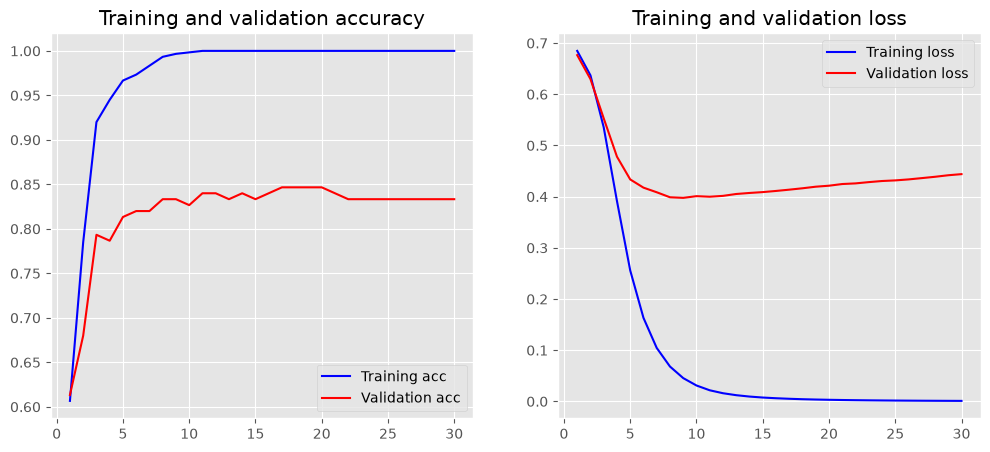

In [31]:
import numpy as np

am_model = build_am_model(am_vocab_size, am_maxlen)
am_history = am_model.fit(am_X_train, am_y_train, epochs=30, verbose=False,
                          validation_split=0.2, batch_size=10)
plot_history(am_history)

am_best_epoch = int(np.argmin(am_history.history['val_loss'])) + 1
print("best epoch:", am_best_epoch)

am_final_model = build_am_model(am_vocab_size, am_maxlen)       # NEW model, new random weights
am_final_model.fit(am_X_train, am_y_train, epochs=am_best_epoch, verbose=False,
                   validation_split=0.2, batch_size=10)
am_nn_acc = am_final_model.evaluate(am_X_test, am_y_test, verbose=False)[1]
print("NN test accuracy: {:.4f}".format(am_nn_acc))

### Step 6: comparison

In [40]:
n_test = len(am_y_test)
diff = am_nn_acc - am_baseline_acc
print("baseline: {:.4f}   neural net: {:.4f}".format(am_baseline_acc, am_nn_acc))
print("difference: {:+.4f}  = {:+.1f} sentences out of {}".format(diff, diff * n_test, n_test))

baseline: 0.7960   neural net: 0.7840
difference: -0.0120  = -3.0 sentences out of 250


**How to read the result (example conclusion; change it to match your numbers):** first calculate how many test sentences the difference means. With 250 test sentences, one sentence is 0.4 percentage points. The random error of an accuracy near 0.8 is about ±2.5 points. If the two accuracies are only a few points apart, we cannot say that one model is really better. We would need a bigger test set, several runs with different random seeds, or cross-validation. If both are similar, the simple and fast logistic regression is a sensible choice. Whichever model has the higher score, your conclusion must use this sentence-count argument.

### Step 7: predictions for new reviews
The new text uses the *same* tokenizer (no new `fit`) and the same `maxlen`. Words that the tokenizer does not know are skipped.

In [42]:
new_reviews = [
    "Great sound quality, works perfectly",
    "Broke after two days. Waste of money",
    "The battery lasts forever and the screen is gorgeous",
]
X_new = pad_sequences(am_tokenizer.texts_to_sequences(new_reviews), padding='post', maxlen=am_maxlen)
probs = am_final_model.predict(X_new, verbose=0).ravel()
for review, p in zip(new_reviews, probs):
    print("{:.2f}  {:8s}  {}".format(p, "positive" if p > 0.5 else "negative", review))

1.00  positive  Great sound quality, works perfectly
0.02  negative  Broke after two days. Waste of money
0.38  negative  The battery lasts forever and the screen is gorgeous


### Optional challenges: solution sketches
**1. Look at the mistakes.** Typical reasons: sarcasm, negation, mixed opinions, or words that were not in the training data.

In [ ]:
probs_test = am_final_model.predict(am_X_test, verbose=0).ravel()
wrong = np.where((probs_test > 0.5).astype(int) != am_y_test)[0]
print(len(wrong), "wrong out of", len(am_y_test))
for i in wrong[:5]:
    print("true={}  p(positive)={:.2f}  {}".format(am_y_test[i], probs_test[i], am_sent_test[i]))

**2. GloVe** (needs `create_embedding_matrix` from Section 3 and the unzipped GloVe files) **and 3. CNN:**

In [ ]:
import keras

# 2. pretrained GloVe vectors, trainable
am_glove = create_embedding_matrix('data/glove.6B.50d.txt', am_tokenizer.word_index, 50)
g_model = Sequential()
g_model.add(layers.Input(shape=(am_maxlen,), dtype='int32'))
g_model.add(layers.Embedding(am_vocab_size, 50,
                             embeddings_initializer=keras.initializers.Constant(am_glove),
                             trainable=True))
g_model.add(layers.GlobalMaxPool1D())
g_model.add(layers.Dense(10, activation='relu'))
g_model.add(layers.Dense(1, activation='sigmoid'))
g_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
g_model.fit(am_X_train, am_y_train, epochs=am_best_epoch, verbose=False, validation_split=0.2, batch_size=10)
print("GloVe test accuracy: {:.4f}".format(g_model.evaluate(am_X_test, am_y_test, verbose=False)[1]))

# 3. 
# (kernel_size 3 needs am_maxlen >= 3)
cnn = Sequential()
cnn.add(layers.Input(shape=(am_maxlen,), dtype='int32'))
cnn.add(layers.Embedding(am_vocab_size, 50))
cnn.add(layers.Conv1D(64, 3, activation='relu'))
cnn.add(layers.GlobalMaxPooling1D())
cnn.add(layers.Dense(10, activation='relu'))
cnn.add(layers.Dense(1, activation='sigmoid'))
cnn.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
cnn.fit(am_X_train, am_y_train, epochs=am_best_epoch, verbose=False, validation_split=0.2, batch_size=10)
print("CNN test accuracy: {:.4f}".format(cnn.evaluate(am_X_test, am_y_test, verbose=False)[1]))

## 7. Summary and self-check

### 📌 The most important ideas
- The Keras text steps: tokenizer → `pad_sequences` → `Embedding` → pooling (or `Conv1D` + pooling) → `Dense` → sigmoid.
- The `Embedding` layer is a trainable lookup table: one row (vector) for each word number. Number 0 is for padding, so `vocab_size = len(word_index) + 1`.
- Global max pooling keeps the strongest signal for each number, but the word order is lost. A `Flatten` model keeps positions but treats each position separately.
- Embeddings can be **learned from scratch** or **pretrained** (GloVe), frozen or trained further. Pretrained vectors help most with little data and good coverage. They do not always win.
- A 1-D convolution filter looks at a window of neighbouring words and finds a pattern wherever it is. Global max pooling keeps the strongest match.
- Use the validation curve to choose the number of epochs. Build a **new** model for the final training.
- With a small test set (250 sentences), a difference of 1–2 points is **noise**.

### 📊 Results of the saved runs (Yelp, 750 training / 250 test sentences)
| Model | Training accuracy* | Test accuracy |
|---|---|---|
| Logistic regression on word counts (baseline, Part A) | not shown | 0.7960 |
| Dense network on word counts (100 epochs, Part A) | 0.9547 | 0.7760 |
| Embedding + Flatten + Dense (20 epochs) | 0.9507 | 0.7480 |
| Embedding + GlobalMaxPool (50 epochs) | 0.9547 | 0.7800 |
| GloVe embeddings, frozen | 0.7440 | 0.7000 |
| GloVe embeddings, trainable | 0.9547 | 0.7520 |
| Conv1D network (10 epochs) | 0.9467 | 0.7680 |

\*measured on all 750 training sentences (including the 150 validation sentences). These are single runs from the old Keras 2 version. Your numbers will be a little different.

**The lesson:** on this small data set, **no neural network beat the simple baseline**. Deep models are best when there is much more data. A baseline tells you if the extra complexity is worth it.

### ⚠️ Common mistakes and how to avoid them
| Mistake | How to avoid it |
|---|---|
| Fitting the tokenizer on test data (leakage) | `fit_on_texts` only on training data. |
| Choosing the model with the best *test* score after many tries | Choose with validation data. Use the test set once, at the end. |
| Running `fit` again and thinking the model starts new | Build a new model (use a function that builds it). |
| Wrong `Input` shape, or no pooling/`Flatten` → shape errors | Print `model.summary()` and check the shapes. |
| Forgetting that number 0 (padding) needs a row (`+ 1`) | `vocab_size = len(word_index) + 1` |
| Trusting a 1–2 point difference on a small test set | Convert it to a number of sentences. Repeat the runs. Use cross-validation. |
| Using old Keras 2 code in Keras 3 (`Tokenizer`, `input_length`, `weights=`) | See the setup section and the "Change note" boxes. |

### ✅ Self-check list
Tick the boxes (double-click this cell and change `[ ]` to `[x]`). If you cannot do something, go back to the section in brackets.
- [ ] I can use a tokenizer, `pad_sequences` and `Embedding` in Keras (Section 2)
- [ ] I can explain what pooling does, and why the word order is lost (Section 2)
- [ ] I can explain frozen and trainable pretrained embeddings (Section 3)
- [ ] I can describe what a Conv1D filter and global max pooling do (Section 4)
- [ ] I finished Exercise B and can explain my conclusion (Sections 5–6)

### 🚀 More practice
- Repeat Exercise B with the **IMDb** or **Yelp** data.
- Run a model 5 times and look at the spread of the test accuracies.
- Train on **all three sources together** (3000 sentences).
- Replace `GlobalMaxPool1D` with `GlobalAveragePooling1D`.
- Try the Keras `TextVectorization` layer instead of `SimpleTokenizer` (see the Keras example in "Learn more", Section 2).
- Read the **Appendix** and try the hyperparameter search.

# 📖 Appendix: Read at Home
Extra material. You do not need it for the exercise. **Note:** part A is from the original lecture notes. The wording is more advanced than in the main part.

## A. Subword tokenization with WordPiece (code walk-through)
*Modern language models cut rare words into pieces instead of using a huge vocabulary. This is a step-by-step version of WordPiece training. It uses only plain Python and does not depend on the rest of the notebook.*

##### Wordpiece Tokenizer (Not embedding but tokenization method)
It is a sort of subwords method, it starts from a small vocabulary including the special tokens used by the model and the initial alphabet. Since it identifies subwords by adding a prefix (like ##), each word is initially split by adding that prefix to all the characters inside the word. So, for instance, "word" gets split like this:
<font color=orange>
w ##o ##r ##d</font>

In [ ]:
word_freqs = {'This': 3, 'is': 2, 'the': 1, 'Hugging': 1, 'Face': 1, 'Course': 1, '.': 4, 'chapter': 1, 'about': 1,
    'tokenization': 1, 'section': 1, 'shows': 1, 'several': 1, 'tokenizer': 1, 'algorithms': 1, 'Hopefully': 1,
    ',': 1, 'you': 1, 'will': 1, 'be': 1, 'able': 1, 'to': 1, 'understand': 1, 'how': 1, 'they': 1, 'are': 1,
    'trained': 1, 'and': 1, 'generate': 1, 'tokens': 1}

In [ ]:
alphabet = []
for word in word_freqs.keys():
    if word[0] not in alphabet:
        alphabet.append(word[0])
    for letter in word[1:]:
        if f"##{letter}" not in alphabet:
            alphabet.append(f"##{letter}")

alphabet.sort()
print(alphabet)

['##a', '##b', '##c', '##d', '##e', '##f', '##g', '##h', '##i', '##k', '##l', '##m', '##n', '##o', '##p', '##r', '##s', '##t', '##u', '##v', '##w', '##y', '##z', ',', '.', 'C', 'F', 'H', 'T', 'a', 'b', 'c', 'g', 'h', 'i', 's', 't', 'u', 'w', 'y']


In [ ]:
splits = {
    word: [c if i == 0 else f"##{c}" for i, c in enumerate(word)]
    for word in word_freqs.keys()
}

print(splits)

{'This': ['T', '##h', '##i', '##s'], 'is': ['i', '##s'], 'the': ['t', '##h', '##e'], 'Hugging': ['H', '##u', '##g', '##g', '##i', '##n', '##g'], 'Face': ['F', '##a', '##c', '##e'], 'Course': ['C', '##o', '##u', '##r', '##s', '##e'], '.': ['.'], 'chapter': ['c', '##h', '##a', '##p', '##t', '##e', '##r'], 'about': ['a', '##b', '##o', '##u', '##t'], 'tokenization': ['t', '##o', '##k', '##e', '##n', '##i', '##z', '##a', '##t', '##i', '##o', '##n'], 'section': ['s', '##e', '##c', '##t', '##i', '##o', '##n'], 'shows': ['s', '##h', '##o', '##w', '##s'], 'several': ['s', '##e', '##v', '##e', '##r', '##a', '##l'], 'tokenizer': ['t', '##o', '##k', '##e', '##n', '##i', '##z', '##e', '##r'], 'algorithms': ['a', '##l', '##g', '##o', '##r', '##i', '##t', '##h', '##m', '##s'], 'Hopefully': ['H', '##o', '##p', '##e', '##f', '##u', '##l', '##l', '##y'], ',': [','], 'you': ['y', '##o', '##u'], 'will': ['w', '##i', '##l', '##l'], 'be': ['b', '##e'], 'able': ['a', '##b', '##l', '##e'], 'to': ['t', '##o'],

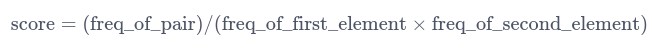

In [ ]:
from collections import defaultdict

def compute_pair_scores(splits):
    letter_freqs = defaultdict(int)
    pair_freqs = defaultdict(int)
    for word, freq in word_freqs.items():
        split = splits[word]
        if len(split) == 1:
            letter_freqs[split[0]] += freq
            continue
        for i in range(len(split) - 1):
            pair = (split[i], split[i + 1])
            letter_freqs[split[i]] += freq
            pair_freqs[pair] += freq
        letter_freqs[split[-1]] += freq

    scores = {
        pair: freq / (letter_freqs[pair[0]] * letter_freqs[pair[1]])
        for pair, freq in pair_freqs.items()
    }
    return scores

In [ ]:
pair_scores = compute_pair_scores(splits)
for i, key in enumerate(pair_scores.keys()):
    print(f"{key}: {pair_scores[key]}")
    if i >= 5:
        break

('T', '##h'): 0.125
('##h', '##i'): 0.03409090909090909
('##i', '##s'): 0.02727272727272727
('i', '##s'): 0.1
('t', '##h'): 0.03571428571428571
('##h', '##e'): 0.011904761904761904


In [ ]:
best_pair = ""
max_score = None
for pair, score in pair_scores.items():
    if max_score is None or max_score < score:
        best_pair = pair
        max_score = score

print(best_pair, max_score)

('a', '##b') 0.2


In [ ]:
alphabet.append("ab")

In [ ]:
def merge_pair(a, b, splits):
    for word in word_freqs:
        split = splits[word]
        if len(split) == 1:
            continue
        i = 0
        while i < len(split) - 1:
            if split[i] == a and split[i + 1] == b:
                merge = a + b[2:] if b.startswith("##") else a + b
                split = split[:i] + [merge] + split[i + 2 :]
            else:
                i += 1
        splits[word] = split
    return splits

In [ ]:
splits = merge_pair("a", "##b", splits)
splits["about"]

['ab', '##o', '##u', '##t']

let's put all step together by looping until we have learned all the merges we want. Let’s aim for a vocab size of 70:

In [ ]:
vocab_size = 70
while len(alphabet) < vocab_size:
    scores = compute_pair_scores(splits)
    best_pair, max_score = "", None
    for pair, score in scores.items():
        if max_score is None or max_score < score:
            best_pair = pair
            max_score = score
    splits = merge_pair(*best_pair, splits)
    new_token = (
        best_pair[0] + best_pair[1][2:]
        if best_pair[1].startswith("##")
        else best_pair[0] + best_pair[1]
    )
    alphabet.append(new_token)

In [ ]:
print(alphabet)

['##a', '##b', '##c', '##d', '##e', '##f', '##g', '##h', '##i', '##k', '##l', '##m', '##n', '##o', '##p', '##r', '##s', '##t', '##u', '##v', '##w', '##y', '##z', ',', '.', 'C', 'F', 'H', 'T', 'a', 'b', 'c', 'g', 'h', 'i', 's', 't', 'u', 'w', 'y', 'ab', '##fu', 'Fa', 'Fac', '##ct', '##ful', '##full', '##fully', 'Th', 'ch', '##hm', 'cha', 'chap', 'chapt', '##thm', 'Hu', 'Hug', 'Hugg', 'sh', 'th', 'is', '##thms', '##za', '##zat', '##ut', '##ta', '##at', '##sta', '##ra', '##rsta']


## B. Hyperparameter search with random search and cross-validation
*Slow (many models are trained) and optional. Needs `pip install scikeras`. **I could not run this part when I prepared the notebook, so it is not tested.***

The settings of a model that you choose yourself (number of filters, kernel size, embedding size, ...) are called **hyperparameters**. There is no rule that always works, so we try different values.
- **Grid search** tries all combinations. It is thorough but slow.
- **Random search** tries random combinations. It is faster.
- **Cross-validation** (here `cv=4`) splits the training data in 4 parts. The model is trained 4 times, each time with another part for validation. The mean score is more stable than one validation score.

`KerasClassifier` from the `scikeras` package makes a Keras model look like a scikit-learn model, so we can use `RandomizedSearchCV`. Arguments for the model-building function are passed with the prefix `model__`.

In [ ]:
# !pip install -q scikeras
import numpy as np
import keras
from keras import layers
from keras.models import Sequential
from keras.utils import pad_sequences
from scikeras.wrappers import KerasClassifier
from sklearn.model_selection import RandomizedSearchCV

def create_model(num_filters, kernel_size, vocab_size, embedding_dim, maxlen):
    m = Sequential()
    m.add(layers.Input(shape=(maxlen,), dtype='int32'))
    m.add(layers.Embedding(vocab_size, embedding_dim))
    m.add(layers.Conv1D(num_filters, kernel_size, activation='relu'))
    m.add(layers.GlobalMaxPooling1D())
    m.add(layers.Dense(10, activation='relu'))
    m.add(layers.Dense(1, activation='sigmoid'))
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return m

# data: the Yelp split from Section 2 (sentences_train, sentences_test, y_train, y_test)
hp_maxlen = 100
hp_tokenizer = SimpleTokenizer(num_words=5000)
hp_tokenizer.fit_on_texts(sentences_train)
hp_X_train = pad_sequences(hp_tokenizer.texts_to_sequences(sentences_train), padding='post', maxlen=hp_maxlen)
hp_X_test = pad_sequences(hp_tokenizer.texts_to_sequences(sentences_test), padding='post', maxlen=hp_maxlen)
hp_vocab_size = len(hp_tokenizer.word_index) + 1

clf = KerasClassifier(model=create_model, epochs=20, batch_size=10, verbose=0,
                      model__num_filters=64, model__kernel_size=5,
                      model__vocab_size=hp_vocab_size, model__embedding_dim=50, model__maxlen=hp_maxlen)

param_grid = dict(model__num_filters=[32, 64, 128],
                  model__kernel_size=[3, 5, 7])

search = RandomizedSearchCV(estimator=clf, param_distributions=param_grid,
                            cv=4, verbose=1, n_iter=5)
search.fit(hp_X_train, y_train)

print("best settings :", search.best_params_)
print("best CV score : {:.4f}".format(search.best_score_))
print("test accuracy : {:.4f}".format(search.score(hp_X_test, y_test)))

*Change notes:* the old notebook looped over all three data sets, wrote results to a file, and used `KerasClassifier(build_fn=..., num_filters=[...])`. It also used the *whole* `df` inside the loop by mistake. This version uses only the Yelp split, the current `scikeras` style (`model=` and the `model__` prefix), and no `input()` prompt. The old saved output was removed.

**What to expect:** like our other models, the best CNN will probably get about 0.75–0.80 test accuracy on this small data set. Compare it with the baseline from Section 2.

# 📚 References and further reading (Part B)
Links were collected in October 2026. I checked only some of them (the StatQuest video, the Keras 3 `Tokenizer` change, and the TensorFlow version information). Please check the others yourself, and tell your instructor if a link is broken.

### Articles and tutorials
- Real Python: [Practical Text Classification With Python and Keras](https://realpython.com/python-keras-text-classification/): the tutorial this notebook is based on.
- Jay Alammar: [The Illustrated Word2vec](https://jalammar.github.io/illustrated-word2vec/).
- Chris Olah: [Understanding Convolutions](http://colah.github.io/posts/2014-07-Understanding-Convolutions/).
- Hugging Face course: [WordPiece tokenization](https://huggingface.co/learn/nlp-course/chapter6/6?fw=pt) (also used for Appendix A).

### Videos
- StatQuest: [Word Embedding and Word2Vec, Clearly Explained](https://www.youtube.com/watch?v=viZrOnJclY0).
- 3Blue1Brown: [Neural networks](https://www.3blue1brown.com/topics/neural-networks) (video series).

### Documentation
- Keras: [The Sequential model](https://keras.io/guides/sequential_model/), [Embedding](https://keras.io/api/layers/core_layers/embedding/), [Conv1D](https://keras.io/api/layers/convolution_layers/convolution1d/), [TextVectorization](https://keras.io/api/layers/preprocessing_layers/text/text_vectorization/), [Migrating to Keras 3](https://keras.io/guides/migrating_to_keras_3/).
- Keras examples: [Using pre-trained word embeddings](https://keras.io/examples/nlp/pretrained_word_embeddings/), [Text classification from scratch](https://keras.io/examples/nlp/text_classification_from_scratch/).
- scikit-learn: [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).
- SciKeras (Appendix B): [documentation](https://adriangb.com/scikeras/stable/).

### Courses
- Google: [Machine Learning Crash Course: Embeddings](https://developers.google.com/machine-learning/crash-course/embeddings) and [Overfitting](https://developers.google.com/machine-learning/crash-course/overfitting/overfitting).

### Data and vectors
- [Sentiment Labelled Sentences (UCI)](https://archive.ics.uci.edu/ml/datasets/Sentiment+Labelled+Sentences), [GloVe (Stanford)](https://nlp.stanford.edu/projects/glove/), [fastText](https://fasttext.cc/).

### Papers and books
- Pennington et al. (2014): [GloVe](https://aclanthology.org/D14-1162/).
- Kim (2014): [Convolutional Neural Networks for Sentence Classification](https://arxiv.org/abs/1408.5882).
- Jurafsky & Martin: [Speech and Language Processing](https://web.stanford.edu/~jurafsky/slp3/) (free draft online).